In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pythtb import TBModel, Lattice, Mesh, WFArray
import matplotlib.transforms as mtransforms
from math import pi
from pythtb.visualization import plot_tbmodel


import pythtb

## Funciones

In [2]:
def germanene_pythtb(Ez, B=[0.005, 0., 0.]):
    # ============================================================
    # PARAMETROS GEOMETRICOS
    # ============================================================

    a = 4.02          # Angstrom, constante de red del honeycomb
    Dz = 0.67           # Angstrom, buckling (referencia geometrica)
    theta = 106.5*pi/180

    # Distancia entre primeros vecinos
    a_nn = a/np.sqrt(3)

    # Parametro onsite p-s
    xi0 = 0.196         # eV


    # ============================================================
    # VECTORES A PRIMEROS VECINOS
    # ============================================================
    # theta = angulo respecto del eje +z
    #
    # d1 = a_nn (sin(theta), 0, cos(theta))
    # d2 = a_nn (-sin(theta)/2, sqrt(3) sin(theta)/2, cos(theta))
    # d3 = a_nn (-sin(theta)/2,-sqrt(3) sin(theta)/2, cos(theta))
    #
    # Con theta > 90°, cos(theta)<0

    d1 = a_nn * np.array([np.sin(theta),    0,  np.cos(theta)])

    d2 = a_nn * np.array([-0.5*np.sin(theta),    np.sqrt(3)/2*np.sin(theta),    np.cos(theta)])

    d3 = a_nn * np.array([-0.5*np.sin(theta),    -np.sqrt(3)/2*np.sin(theta),    np.cos(theta)])


    # ============================================================
    # COSENOS DIRECTORES
    # ============================================================

    def direction_cosines(d):
        """Devuelve (l,m,n) para el vector de enlace d."""
        norm = np.linalg.norm(d)
        return d[0]/norm, d[1]/norm, d[2]/norm


    (l1, m1, n1) = direction_cosines(d1)
    (l2, m2, n2) = direction_cosines(d2)
    (l3, m3, n3) = direction_cosines(d3)


    # ============================================================
    # PARAMETROS DE SLATER-KOSTER
    # ============================================================

    VssS = -1.79       # <s|H|s> sigma, eV
    VspS =  2.36       # <s|H|p> sigma, eV
    VppS =  4.15       # <p|H|p> sigma, eV
    VppP = -1.04       # <p|H|p> pi,    eV


    # ============================================================
    # MATRIZ DE HOPPING SLATER-KOSTER
    #
    # Base:
    #       | s, px, py, pz >
    #
    # T_j[mu,nu] =
    # < mu, A | H | nu, B_j >
    #
    # para el enlace A -> B_j.
    # ============================================================

    def hopping_SK(l, m, n):
        """
        Matriz 4x4 de Slater-Koster para un enlace cuya dirección
        tiene cosenos directores (l,m,n).

        Base: [s, px, py, pz]

        Convención usada:
            <s|p_alpha> = direction_cosine * VspS
            <p_alpha|s> = -direction_cosine * VspS

        Los elementos p-p siguen la tabla estándar SK.
        """

        T = np.zeros((4, 4), dtype=float)

        # --------------------------------------------------------
        # s-s
        # --------------------------------------------------------

        T[0, 0] = VssS


        # --------------------------------------------------------
        # s-p
        # --------------------------------------------------------
        # <s|px>, <s|py>, <s|pz>

        T[0, 1] =  l * VspS
        T[0, 2] =  m * VspS
        T[0, 3] =  n * VspS


        # --------------------------------------------------------
        # p-s
        # --------------------------------------------------------
        # Debido a la paridad del orbital p:
        #
        # <px|s> = -l VspS
        # <py|s> = -m VspS
        # <pz|s> = -n VspS

        T[1, 0] = -l * VspS
        T[2, 0] = -m * VspS
        T[3, 0] = -n * VspS


        # --------------------------------------------------------
        # p-p
        # --------------------------------------------------------

        # diagonal
        T[1, 1] = l*l * VppS + (1-l*l) * VppP
        T[2, 2] = m*m * VppS + (1-m*m) * VppP
        T[3, 3] = n*n * VppS + (1-n*n) * VppP

        # fuera de diagonal
        T[1, 2] = l*m * (VppS - VppP)
        T[2, 1] = T[1, 2]

        T[1, 3] = l*n * (VppS - VppP)
        T[3, 1] = T[1, 3]

        T[2, 3] = m*n * (VppS - VppP)
        T[3, 2] = T[2, 3]


        return T


    # ============================================================
    # MATRICES DE HOPPING PARA LOS TRES PRIMEROS VECINOS
    # ============================================================

    T1 = hopping_SK(l1, m1, n1)
    T2 = hopping_SK(l2, m2, n2)
    T3 = hopping_SK(l3, m3, n3)



    # --------------------------------------------------------
    # VECTORES PRIMITIVOS
    # --------------------------------------------------------

    # Honeycomb:
    #
    # a1 = a (1,0)
    # a2 = a (1/2,sqrt(3)/2)

    lat_vecs = [
        [a, 0.0],
        [a/2.0, a*np.sqrt(3.0)/2.0]
    ]


    # --------------------------------------------------------
    # POSICIONES DE LOS ORBITALES
    # --------------------------------------------------------

    # A se toma como origen.
    #
    # B se encuentra desplazado respecto de A por la
    # proyección in-plane de uno de los primeros vecinos.
    #
    # Para el modelo de Hattori podemos tomar como referencia
    # el primer enlace A -> B.

    orb_vecs = [
        [0.0, 0.0],   # A,s
        [0.0, 0.0],   # A,px
        [0.0, 0.0],   # A,py
        [0.0, 0.0],   # A,pz

        [1./3., 1./3.],     # B,s
        [1./3., 1./3.],     # B,px
        [1./3., 1./3.],     # B,py
        [1./3., 1./3.],     # B,pz
    ]


    # --------------------------------------------------------
    # LATTICE
    # --------------------------------------------------------

    lat = Lattice(
        lat_vecs=lat_vecs,
        orb_vecs=orb_vecs,
        periodic_dirs=[0,1]
    )

    model = TBModel(
        lattice=lat,
        spinful=True
    )

    sx=np.array([0.,1.,0.,0])
    sy=np.array([0.,0.,1.,0])
    sz=np.array([0.,0.,0.,1])

    # ========================================================
    # ON-SITE ENERGIES
    # ========================================================

    eps_s = -9.00
    eps_p = -3.39

    # Campo eléctrico:
    #
    # V = Ez * z / 2
    #
    # A -> +V
    # B -> -V

    V = Ez * Dz / 2.0
    #Ajuta nivel de Fermi a 0

    # FL=-3.7113856547660458
    FL=-4.75
    
    onsite_A = [
        eps_s + V-FL,
        eps_p + V-FL,
        eps_p + V-FL,
        eps_p + V-FL
    ]

    onsite_B = [
        eps_s - V-FL,
        eps_p - V-FL,
        eps_p - V-FL,
        eps_p - V-FL
    ]

    magnetic= [
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz])
    ]

    model.set_onsite(onsite_A + onsite_B, mode='add')

    model.set_onsite(magnetic, mode='add')

    # ========================================================
    # MATRICES DE IDENTIDAD EN SPIN
    # ========================================================

    sigma0 = np.eye(2, dtype=complex)


    # ========================================================
    # HOPPING DE PRIMEROS VECINOS
    # ========================================================

    # Cada Tj es una matriz 4x4 orbital.
    #
    # Para cada hopping orbital -> orbital:
    #
    # amplitud = t_{alpha,beta} * I_spin
    #
    # PythTB genera automáticamente el conjugado hermítico.

    T_list = [T1, T2, T3]


    # --------------------------------------------------------
    # VECTORES DE CELDA PARA LOS TRES VECINOS
    # --------------------------------------------------------

    # El vecino 1 está en la celda [0,0].
    #
    # Los otros dos se encuentran en las celdas vecinas
    # correspondientes.

    neighbor_cells = [
        [0, 0],
        [-1, 0],
        [0, -1]
    ]


    # --------------------------------------------------------
    # Hoppings A -> B
    # --------------------------------------------------------

    for T, R in zip(T_list, neighbor_cells):

        for alpha in range(4):

            for beta in range(4):

                amp = T[alpha, beta] * sigma0

                model.set_hop(amp,  alpha,  4 + beta,   ind_R=R)    #hopping de A a B requiere pasar por las 4 bases del medio


    # ========================================================
    # SPIN-ORBIT COUPLING
    # ========================================================

    # --------------------------------------------------------
    # SOC entre orbitales p
    # --------------------------------------------------------

    # H_SO = xi0/2 * epsilon_{alpha beta gamma}
    #        (-i sigma_gamma) + H.c.
    #
    # Las parejas relevantes son:
    #
   
    # A sublattice
    model.set_hop(-1j * xi0/2.0 * sz,   1, 2,   ind_R=[0,0],    mode="add")     # px <-> py  mediante sigma_z

    model.set_hop(-1j * xi0/2.0 * sx,   2, 3,   ind_R=[0,0],    mode="add")     # py <-> pz  mediante sigma_x

    model.set_hop(-1j * xi0/2.0 * sy,   3, 1,   ind_R=[0,0],    mode="add")     # pz <-> px  mediante sigma_y


    # B sublattice
    model.set_hop(-1j * xi0/2.0 * sz,   5, 6,   ind_R=[0,0],    mode="add")     # px <-> py  mediante sigma_z

    model.set_hop(-1j * xi0/2.0 * sx,   6, 7,   ind_R=[0,0],    mode="add")     # py <-> pz  mediante sigma_x

    model.set_hop(-1j * xi0/2.0 * sy,   7, 5,   ind_R=[0,0],    mode="add")     # pz <-> px  mediante sigma_y


    return model

In [3]:
def gap_2d(model, mallado=240):
    n_occ = model.norb

    ks = np.linspace(-0.5, 0.5, mallado, endpoint=False)   #con endpoint false, el mallado tiene que ser multiplo de 6 para contener a K
    k_pts = [[kx, ky] for kx in ks for ky in ks]

    evals = model.solve_ham(k_pts=k_pts)  # (Nk=mallado**2, 16)

    val = evals[:, n_occ - 1]
    cond = evals[:, n_occ]

    return np.min(cond - val)

def gap_1d(model, mallado=240):
    n_occ = model.norb
    #primero veamos en un punto para ahorrar pasos
    evals = model.solve_ham(k_pts=0)    
    gap=np.min(evals[n_occ]) - np.max(evals[n_occ - 1])  
    if gap<=0:
        return 0
    
    k_vals = np.linspace(0, 1, mallado, endpoint=False)
    k_pts = [[k] for k in k_vals]

    evals = model.solve_ham(k_pts=k_pts)  # (mallado, 16)
    gap=np.min(evals[:, n_occ]) - np.max(evals[:, n_occ - 1])           #gap indirecto es el más adecuado para este análisis
    if gap<0:
        return 0
    return gap

In [4]:
#curvas teoricas del gapless
def theoric_curves(E_plot):

    # #parametro aprox donde se cierra el gap para B=0
    # E_c=46./450.

    # #parametro fitteado con E=0.4 cuando B=0.15
    # A=0.15**2/(0.4**2-E_c**2)

    # B1 = np.sqrt(A*(E_plot**2 - E_c**2))
    # plt.plot(E_plot, B1, 'r--', label=r"$E^2 - B^2/A = C^2$",linewidth=0.5)

    # #curva B=aE
    # B2= E_plot*np.sqrt(A)
    # plt.plot(E_plot, B2, 'w-', label=r"$B=aE$", linewidth=0.5)
    # plt.legend()
    return


## Mapa de Gaps 1D y 2D

In [ ]:
mesh = 100

B_min = 0
B_max = 0.26
E_min = 0
E_max = 0.8

calcula

In [ ]:
from joblib import Parallel, delayed
import numpy as np


def compute_point(i, j, B, e):
    
    model = germanene_pythtb(e, B=[B, 0, 0])
    gap2d = gap_2d(model)

    fin_model_1d = model.make_finite(
        periodic_dirs=[0],
        num_cells=[35],
        glue_edges=[False]
    )
    gap1d = gap_1d(fin_model_1d)

    return i, j, gap2d, gap1d

In [10]:
E_vals = np.linspace(E_min, E_max, mesh)
B_vals = np.linspace(B_min, B_max, mesh)

gap_map2D = np.zeros((mesh, mesh))
gap_map1D = np.zeros((mesh, mesh))

tasks = [
    (i, j, B, e)
    for i, B in enumerate(B_vals)
    for j, e in enumerate(E_vals)
]

results = Parallel(n_jobs=-1, verbose=10)(
    delayed(compute_point)(i, j, B, e)
    for i, j, B, e in tasks
)

for i, j, gap2d, gap1d in results:
    gap_map2D[i, j] = gap2d
    gap_map1D[i, j] = gap1d


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done  17 tasks      | elapsed:  3.0min
[Parallel(n_jobs=-1)]: Done  24 tasks      | elapsed:  3.6min
[Parallel(n_jobs=-1)]: Done  33 tasks      | elapsed:  5.1min
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:  6.1min
[Parallel(n_jobs=-1)]: Done  53 tasks      | elapsed:  8.1min
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:  9.3min
[Parallel(n_jobs=-1)]: Done  77 tasks      | elapsed: 11.1min
[Parallel(n_jobs=-1)]: Done  90 tasks      | elapsed: 12.6min
[Parallel(n_jobs=-1)]: Done 105 tasks      | elapsed: 14.6min
[Parallel(n_jobs=-1)]: Done 120 tasks      | elapsed: 16.0min
[Parallel(n_jobs=-1)]: Done 137 tasks      | elapsed: 17.7min
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed: 19.2min
[Parallel(n_jobs=-1)]: Done 173 tasks      | elapsed: 21

guardado

In [11]:
np.save("gap_map1D.npy", gap_map1D)
np.save("gap_map2D.npy", gap_map2D)


In [12]:
np.save("B_vals.npy", B_vals)
np.save("E_vals.npy", E_vals)

ploteo

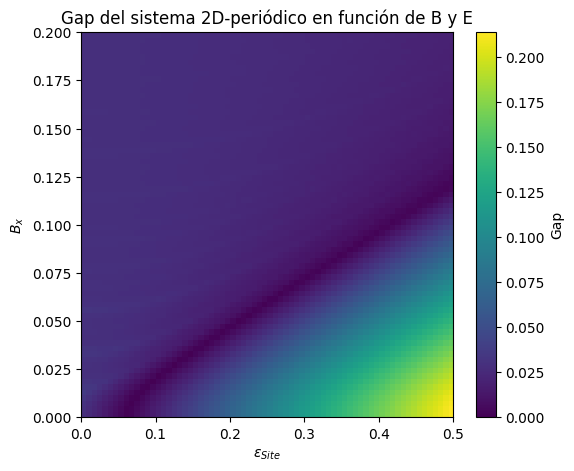

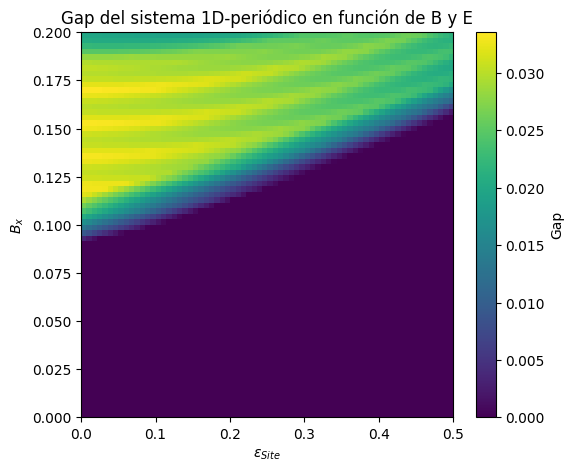

In [13]:
gap_map1D = np.load("gap_map1D.npy")
gap_map2D = np.load("gap_map2D.npy")
B_vals = np.load("B_vals.npy")
E_vals = np.load("E_vals.npy")

# '''-----------------------------------2D----------------------------------'''
plt.figure(figsize=(6,5))
plt.imshow(
    gap_map2D,
    origin="lower",
    aspect="auto",
    vmin=0,
    extent=[E_vals[0], E_vals[-1], B_vals[0], B_vals[-1]]
)
plt.colorbar(label="Gap")
plt.xlabel(r"$\epsilon_{Site}$")
plt.ylabel(r"$B_x$")
plt.title("Gap del sistema 2D-periódico en función de B y E")

# E_plot = np.linspace(E_vals[0], E_vals[-1], 500)
# theoric_curves(E_plot)
plt.ylim(top=B_max)

plt.show()
'''-----------------------------------1D----------------------------------'''
plt.figure(figsize=(6,5))
plt.imshow(
    gap_map1D,
    origin="lower",
    aspect="auto",
    vmin=0,
    extent=[E_vals[0], E_vals[-1], B_vals[0], B_vals[-1]]
)
plt.colorbar(label="Gap")
plt.xlabel(r"$\epsilon_{Site}$")
plt.ylabel(r"$B_x$")
plt.title("Gap del sistema 1D-periódico en función de B y E")

# E_plot = np.linspace(E_vals[0], E_vals[-1], 500)
# theoric_curves(E_plot)
# plt.ylim(top=B_max)

plt.show()
